<a href="https://colab.research.google.com/github/DAustinGit/SolubilityML/blob/main/solubility_ML_expanded_properties.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [71]:
import pandas as pd
df = pd.read_csv('//root//mol_properties.csv')
print (df.head())

                      Compound ID  measured log(solubility:mol/L)  \
0       1,1,1,2-Tetrachloroethane                           -2.18   
1           1,1,1-Trichloroethane                           -2.00   
2       1,1,2,2-Tetrachloroethane                           -1.74   
3           1,1,2-Trichloroethane                           -1.48   
4  1,1,2-Trichlorotrifluoroethane                           -3.04   

                SMILES  num_Rotatable_Bonds  num_H_Bond_Acceptors  \
0       ClCC(Cl)(Cl)Cl                    0                     0   
1         CC(Cl)(Cl)Cl                    0                     0   
2       ClC(Cl)C(Cl)Cl                    1                     0   
3           ClCC(Cl)Cl                    1                     0   
4  FC(F)(Cl)C(F)(Cl)Cl                    1                     0   

   num_H_Bond_Doners  num_Nitrogen_Oxygen  mol_weight    LogP  \
0                  0                    0     167.850  2.5954   
1                  0                    

#Data preparation


In [72]:
   # Y is feature used for training
X = df.drop(['measured log(solubility:mol/L)', 'Compound ID', 'SMILES'], axis=1)   #X is the feature we are predicting drop logS and axis = 1 --> work in coluns
print (Y.head())
print (X.head())

0   -2.18
1   -2.00
2   -1.74
3   -1.48
4   -3.04
Name: measured log(solubility:mol/L), dtype: float64
   num_Rotatable_Bonds  num_H_Bond_Acceptors  num_H_Bond_Doners  \
0                    0                     0                  0   
1                    0                     0                  0   
2                    1                     0                  0   
3                    1                     0                  0   
4                    1                     0                  0   

   num_Nitrogen_Oxygen  mol_weight    LogP  aromatic proportion  
0                    0     167.850  2.5954                  0.0  
1                    0     133.405  2.3765                  0.0  
2                    0     167.850  2.5938                  0.0  
3                    0     133.405  2.0289                  0.0  
4                    0     187.375  2.9189                  0.0  


###split the dataset into test and training sets


In [73]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split (X, Y, test_size= 0.2, random_state = 100) #splits the data for train and test sets testing set is 20% of data
print (X_train)

     num_Rotatable_Bonds  num_H_Bond_Acceptors  num_H_Bond_Doners  \
107                    5                     0                  0   
378                    0                     4                  2   
529                    0                     3                  2   
546                    0                     3                  2   
320                    2                     1                  0   
..                   ...                   ...                ...   
802                    1                     2                  0   
53                     3                     0                  0   
350                    0                     0                  0   
79                    10                     1                  1   
792                    3                     3                  2   

     num_Nitrogen_Oxygen  mol_weight     LogP  aromatic proportion  
107                    0     112.216  3.14280             0.000000  
378                    6     142.

#Model Building

##Linear Regression


**trianing the model**

In [74]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X_train, Y_train)


LinearRegression()

**applying the model to make predictions**

In [75]:
Y_lr_train_pred = lr.predict(X_train)
Y_lr_test_pred = lr.predict(X_test)

In [76]:
print (Y_lr_train_pred)

[ -2.97862611   0.74515679  -0.83479478  -0.42203418  -1.50989646
  -2.73817451  -2.37897857  -4.63918186  -5.09281714  -2.14362146
  -2.97286271  -4.32304113  -1.23033563  -2.75075704  -7.26044747
  -2.18923185  -3.86718557  -2.7047417   -3.66361739  -3.69052476
  -2.52857736  -3.21400959  -2.3468788   -2.32085409  -0.49323739
  -6.53759979  -3.09302583  -2.10799693  -7.20711691  -1.71324361
  -4.96427203  -0.75240118  -7.26044747  -1.73406291  -2.84545384
  -4.99803334  -4.19325433  -2.31119775  -3.86584717  -2.72335041
  -1.88545349  -2.55088165  -2.79853118  -1.60560084  -3.99245451
  -1.25292665  -0.24264347  -5.48174662  -3.07690009   0.35104237
  -3.08150459  -4.62149347  -0.38666378  -4.99040295  -6.15127474
  -2.7992311   -3.69961632  -2.48752905  -2.61636108  -3.09852526
  -2.56131694  -0.81969331  -4.4911002   -3.42059298  -3.38598676
  -9.44344186  -6.6118093   -1.87979452  -4.70906674  -1.72630511
  -1.73901113  -3.32101209  -1.10924613  -1.59290624  -1.50989646
  -5.30057

In [77]:
print (Y_lr_test_pred)

[ -2.99976873  -7.98678451  -2.52857736  -1.93240644  -2.1203783
  -1.11693272  -0.39375832  -0.68917705  -5.81308443  -4.77739347
  -3.90062949  -2.14362146  -1.50801605  -1.60560084  -4.60717858
  -2.02798704  -1.36006102  -3.01693699  -3.63610806  -5.43315468
  -3.1077216   -5.09281714  -5.76320768  -2.21139359  -3.49459671
  -4.80755091  -3.20395217  -4.48199206  -4.09651566   0.0413507
  -1.75949733  -4.15876456  -2.35165828  -1.39435644  -0.42830915
  -1.68309296  -2.56910339  -2.80790949  -4.82284092  -1.6906075
  -1.71206741  -1.70621231  -6.74828855  -7.62189641  -5.99372892
  -4.5402284   -3.50736603   1.29854028  -0.01888052  -2.43144287
  -2.00943012  -4.80755091   0.73854606  -2.71104066  -4.99654007
  -2.39752818  -7.98678451  -1.32247583  -1.28233094  -5.09281714
  -2.48028748  -2.76367685  -2.42630029  -2.58323343  -1.82741737
  -1.3187586   -3.6376554   -2.90778158  -1.7316006   -3.22685447
  -3.34686551  -0.52598509  -5.51459719  -0.47825353  -6.97130606
 -10.90420319

###**evaluate model performance**
evaluate the mean square error (MSE) and R^2 error (R2)

In [78]:
from sklearn.metrics import mean_squared_error, r2_score
lr_train_mse = mean_squared_error(Y_train, Y_lr_train_pred)
lr_train_r2 = r2_score(Y_train, Y_lr_train_pred)
lr_test_mse = mean_squared_error(Y_test, Y_lr_test_pred)
lr_test_r2 = r2_score(Y_test, Y_lr_test_pred)

print ('LR MSE (Train): ',lr_train_mse)
print ('LR R2 (Train): ',lr_train_r2)
print ('LR MSE (Test): ',lr_test_mse)
print ('LR R2 (Test): ',lr_test_r2)
print

LR MSE (Train):  0.936182705803999
LR R2 (Train):  0.7811828901523954
LR MSE (Test):  1.0459564511981412
LR R2 (Test):  0.783943601347953


<function print(*args, sep=' ', end='\n', file=None, flush=False)>

In [79]:
lr_results = pd.DataFrame(['Linear regression', lr_train_mse, lr_train_r2, lr_test_mse, lr_test_r2]).transpose()
lr_results.columns = ['methods', 'Training MSE', 'Training R2', 'Test MSE', 'test R2']
lr_results

,methods,Training MSE,Training R2,Test MSE,test R2
0,Linear regression,0.936183,0.781183,1.045956,0.783944


## **Random Forest**
use RandomForestRegressor because Y (logS) is quantitative if its catagporical use RandomForestClassifier

In [80]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor (max_depth=3, random_state=100)
rf.fit(X_train, Y_train)

RandomForestRegressor(max_depth=3, random_state=100)

### Applying the model to make predictions





In [81]:
Y_rf_train_pred = rf.predict(X_train)
Y_rf_test_pred = rf.predict(X_test)

###**evaluate model performance**
evaluate the mean square error (MSE) and R^2 error (R2)

In [82]:
from sklearn.metrics import mean_squared_error, r2_score
rf_train_mse = mean_squared_error(Y_train, Y_rf_train_pred)
rf_train_r2 = r2_score(Y_train, Y_rf_train_pred)
rf_test_mse = mean_squared_error(Y_test, Y_rf_test_pred)
rf_test_r2 = r2_score(Y_test, Y_rf_test_pred)

print ('LR MSE (Train): ',rf_train_mse)
print ('LR R2 (Train): ',rf_train_r2)
print ('LR MSE (Test): ',rf_test_mse)
print ('LR R2 (Test): ',rf_test_r2)

LR MSE (Train):  0.6997942866476795
LR R2 (Train):  0.8364347446894941
LR MSE (Test):  1.0370922172064638
LR R2 (Test):  0.7857746283193505


In [83]:
rf_results = pd.DataFrame(['Random Forest', rf_train_mse, rf_train_r2, rf_test_mse, rf_test_r2]).transpose()
rf_results.columns = ['methods', 'Training MSE', 'Training R2', 'Test MSE', 'test R2']
rf_results

,methods,Training MSE,Training R2,Test MSE,test R2
0,Random Forest,0.699794,0.836435,1.037092,0.785775


## Stoichastic gradient descent


*   it is important to scale data before
*   we make a pipeline and pass in the standard scalar method



In [84]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import SGDRegressor
from sklearn.preprocessing import StandardScaler

clf = make_pipeline(StandardScaler(), SGDRegressor(penalty= 'l2', max_iter=1000))
clf.fit(X_train, Y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('sgdregressor', SGDRegressor())])

### Applying the model to make predictions








In [85]:
Y_clf_train_pred = clf.predict(X_train)
Y_clf_test_pred = clf.predict(X_test)

###evaluate model performance
evaluate the mean square error (MSE) and R^2 error (R2)

In [86]:
from sklearn.metrics import mean_squared_error, r2_score
clf_train_mse = mean_squared_error(Y_train, Y_clf_train_pred)
clf_train_r2 = r2_score(Y_train, Y_clf_train_pred)
clf_test_mse = mean_squared_error(Y_test, Y_clf_test_pred)
clf_test_r2 = r2_score(Y_test, Y_clf_test_pred)

print ('LR MSE (Train): ',clf_train_mse)
print ('LR R2 (Train): ',clf_train_r2)
print ('LR MSE (Test): ',clf_test_mse)
print ('LR R2 (Test): ',clf_test_r2)

LR MSE (Train):  0.9432021846535739
LR R2 (Train):  0.7795422039220498
LR MSE (Test):  1.0403249660282818
LR R2 (Test):  0.7851068604907869


In [87]:
clf_results = pd.DataFrame(['Stoichastic Gradient Descent', clf_train_mse, clf_train_r2, clf_test_mse, clf_test_r2]).transpose()
clf_results.columns = ['methods', 'Training MSE', 'Training R2', 'Test MSE', 'test R2']
clf_results

,methods,Training MSE,Training R2,Test MSE,test R2
0,Stoichastic Gradient Descent,0.943202,0.779542,1.040325,0.785107


##Bayesian Ridge Regression

In [88]:
from sklearn import linear_model
br = linear_model.BayesianRidge()
br.fit(X_train, Y_train)


BayesianRidge()

### Applying the model to make predictions








In [89]:
Y_br_train_pred = br.predict(X_train)
Y_br_test_pred = br.predict(X_test)

###evaluate model performance
evaluate the mean square error (MSE) and R^2 error (R2)

In [90]:
from sklearn.metrics import mean_squared_error, r2_score
br_train_mse = mean_squared_error(Y_train, Y_br_train_pred)
br_train_r2 = r2_score(Y_train, Y_br_train_pred)
br_test_mse = mean_squared_error(Y_test, Y_br_test_pred)
br_test_r2 = r2_score(Y_test, Y_br_test_pred)

print ('LR MSE (Train): ',br_train_mse)
print ('LR R2 (Train): ',br_train_r2)
print ('LR MSE (Test): ',br_test_mse)
print ('LR R2 (Test): ',br_test_r2)

LR MSE (Train):  0.9363157570900296
LR R2 (Train):  0.7811517916310382
LR MSE (Test):  1.0429265922379471
LR R2 (Test):  0.7845694595417749


In [91]:
br_results = pd.DataFrame(['Beyesian Ridge Regression', br_train_mse, br_train_r2, br_test_mse, br_test_r2]).transpose()
br_results.columns = ['methods', 'Training MSE', 'Training R2', 'Test MSE', 'test R2']
br_results

,methods,Training MSE,Training R2,Test MSE,test R2
0,Beyesian Ridge Regression,0.936316,0.781152,1.042927,0.784569


## K-nearest neighbours

In [92]:
from sklearn.neighbors import KNeighborsRegressor
kn = KNeighborsRegressor(n_neighbors=5)
kn.fit (X_train,Y_train)


KNeighborsRegressor()

### Applying the model to make predictions


In [93]:
Y_kn_train_pred = kn.predict(X_train)
Y_kn_test_pred = kn.predict(X_test)

In [94]:
from sklearn.metrics import mean_squared_error, r2_score
kn_train_mse = mean_squared_error(Y_train, Y_kn_train_pred)
kn_train_r2 = r2_score(Y_train, Y_kn_train_pred)
kn_test_mse = mean_squared_error(Y_test, Y_kn_test_pred)
kn_test_r2 = r2_score(Y_test, Y_kn_test_pred)

print ('LR MSE (Train): ',kn_train_mse)
print ('LR R2 (Train): ',kn_train_r2)
print ('LR MSE (Test): ',kn_test_mse)
print ('LR R2 (Test): ',kn_test_r2)

LR MSE (Train):  0.9706280080874317
LR R2 (Train):  0.773131874632925
LR MSE (Test):  1.2944905114410479
LR R2 (Test):  0.7326055423523391


In [95]:
kn_results = pd.DataFrame(['K-Nearest neighbours', kn_train_mse, kn_train_r2, kn_test_mse, kn_test_r2]).transpose()
kn_results.columns = ['methods', 'Training MSE', 'Training R2', 'Test MSE', 'test R2']
kn_results

,methods,Training MSE,Training R2,Test MSE,test R2
0,K-Nearest neighbours,0.970628,0.773132,1.294491,0.732606


## Bayesian Ridge with standard scalar pipeline

In [96]:
from sklearn import linear_model
from sklearn.preprocessing import StandardScaler

brp = make_pipeline(StandardScaler(), linear_model.BayesianRidge())
brp.fit(X_train, Y_train)




brp.fit(X_train, Y_train)


Pipeline(steps=[('standardscaler', StandardScaler()),
                ('bayesianridge', BayesianRidge())])

### Applying the model to make predictions


In [97]:
Y_brp_train_pred = brp.predict(X_train)
Y_brp_test_pred = brp.predict(X_test)

###evaluate model performance
evaluate the mean square error (MSE) and R^2 error (R2)

In [98]:
from sklearn.metrics import mean_squared_error, r2_score
brp_train_mse = mean_squared_error(Y_train, Y_brp_train_pred)
brp_train_r2 = r2_score(Y_train, Y_brp_train_pred)
brp_test_mse = mean_squared_error(Y_test, Y_brp_test_pred)
brp_test_r2 = r2_score(Y_test, Y_brp_test_pred)

print ('LR MSE (Train): ',brp_train_mse)
print ('LR R2 (Train): ',brp_train_r2)
print ('LR MSE (Test): ',brp_test_mse)
print ('LR R2 (Test): ',brp_test_r2)

LR MSE (Train):  0.9362933019010541
LR R2 (Train):  0.7811570401573379
LR MSE (Test):  1.0442352666499783
LR R2 (Test):  0.7842991352083406


In [99]:
brp_results = pd.DataFrame(['Beyesian Ridge Pipeline', brp_train_mse, brp_train_r2, brp_test_mse, brp_test_r2]).transpose()
brp_results.columns = ['methods', 'Training MSE', 'Training R2', 'Test MSE', 'test R2']
brp_results

,methods,Training MSE,Training R2,Test MSE,test R2
0,Beyesian Ridge Pipeline,0.936293,0.781157,1.044235,0.784299


## BR KNN Ensemble

In [100]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn import linear_model
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import StackingRegressor
from sklearn.model_selection import GridSearchCV

base_learners = [
    ('lr', linear_model.BayesianRidge()),
    ('knn', KNeighborsRegressor())
]

stacking_ensemble = StackingRegressor(
    estimators=base_learners,
    final_estimator=RidgeCV(),
    cv = 3


)
pipeline = Pipeline([
  ('scaler', StandardScaler()),
  ('stack', stacking_ensemble)
])

param_grid = {


    # Tune the KNN model hidden inside the stack step
    'stack__knn__n_neighbors': [3, 5, 7, 11],

    # Tune the weights parameter of the KNN model inside the stack step
    'stack__knn__weights': ['uniform', 'distance']
}
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train, Y_train)

# 6. Output the results
print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best CV R² Score: {grid_search.best_score_:.4f}")
print(f"Test Set R² Score: {grid_search.score(X_test, Y_test):.4f}")


Best Parameters: {'stack__knn__n_neighbors': 3, 'stack__knn__weights': 'distance'}
Best CV R² Score: 0.8825
Test Set R² Score: 0.8813


In [101]:
Y_bk_train_pred = grid_search.predict(X_train)
Y_bk_test_pred = grid_search.predict(X_test)

In [102]:
from sklearn.metrics import mean_squared_error, r2_score
bk_train_mse = mean_squared_error(Y_train, Y_bk_train_pred)
bk_train_r2 = r2_score(Y_train, Y_bk_train_pred)
bk_test_mse = mean_squared_error(Y_test, Y_bk_test_pred)
bk_test_r2 = r2_score(Y_test, Y_bk_test_pred)

print ('LR MSE (Train): ',bk_train_mse)
print ('LR R2 (Train): ',bk_train_r2)
print ('LR MSE (Test): ',bk_test_mse)
print ('LR R2 (Test): ',bk_test_r2)

LR MSE (Train):  0.0802376201433773
LR R2 (Train):  0.9812457931213914
LR MSE (Test):  0.5744892571602026
LR R2 (Test):  0.881331503023724


In [103]:
bk_results = pd.DataFrame(['BR KNN Ensemble', bk_train_mse, bk_train_r2, bk_test_mse, bk_test_r2]).transpose()
bk_results.columns = ['methods', 'Training MSE', 'Training R2', 'Test MSE', 'test R2']
bk_results

,methods,Training MSE,Training R2,Test MSE,test R2
0,BR KNN Ensemble,0.080238,0.981246,0.574489,0.881332


## Gaussian Process Regressor

In [104]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

kernel = 1*RBF(length_scale=[1.0,1.0,1.0,1.0,1.0], length_scale_bounds=(1e-2, 1e2))

gpr = make_pipeline(StandardScaler(), GaussianProcessRegressor(kernel=kernel,n_restarts_optimizer=1, normalize_y=True,  alpha=1e-3))
gpr.fit(X_train, Y_train)






ValueError: Anisotropic kernel must have the same number of dimensions as data (5!=7)

In [ ]:
Y_gpr_train_pred = gpr.predict(X_train)
Y_gpr_test_pred = gpr.predict(X_test)

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score
gpr_train_mse = mean_squared_error(Y_train, Y_gpr_train_pred)
gpr_train_r2 = r2_score(Y_train, Y_gpr_train_pred)
gpr_test_mse = mean_squared_error(Y_test, Y_gpr_test_pred)
gpr_test_r2 = r2_score(Y_test, Y_gpr_test_pred)

print ('GPR MSE (Train): ',gpr_train_mse)
print ('GPR R2 (Train): ',gpr_train_r2)
print ('GPR MSE (Test): ',gpr_test_mse)
print ('GPR R2 (Test): ',gpr_test_r2)

In [ ]:
gpr_results = pd.DataFrame(['Gaussian Process Regressor', gpr_train_mse, gpr_train_r2, gpr_test_mse, gpr_test_r2]).transpose()
gpr_results.columns = ['methods', 'Training MSE', 'Training R2', 'Test MSE', 'test R2']
gpr_results

##Model Comparison

In [ ]:
df_models = pd.concat([lr_results, rf_results, clf_results, br_results, brp_results, kn_results, bk_results, gpr_results], axis=0).reset_index(drop=True)
df_models

#Data visualisation of prediction results


##Linear Regression

Text(0.5, 0, 'Experimental LogS')

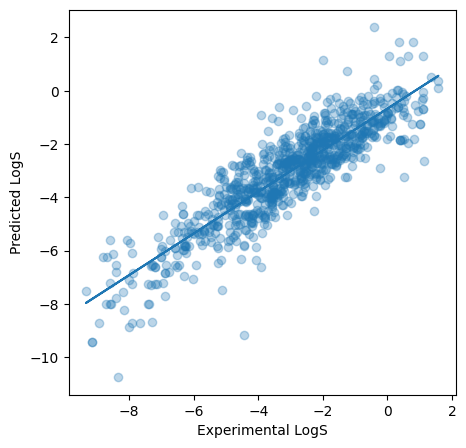

In [105]:
import matplotlib.pyplot as plt
import numpy as np
plt.figure(figsize=(5,5))
plt.scatter (x=Y_train, y = Y_lr_train_pred, alpha=0.3)
z = np.polyfit(Y_train, Y_lr_train_pred,1)
p = np.poly1d(z)

plt.plot(Y_train, p(Y_train))
plt.ylabel('Predicted LogS')
plt.xlabel('Experimental LogS')

###Residuals plot

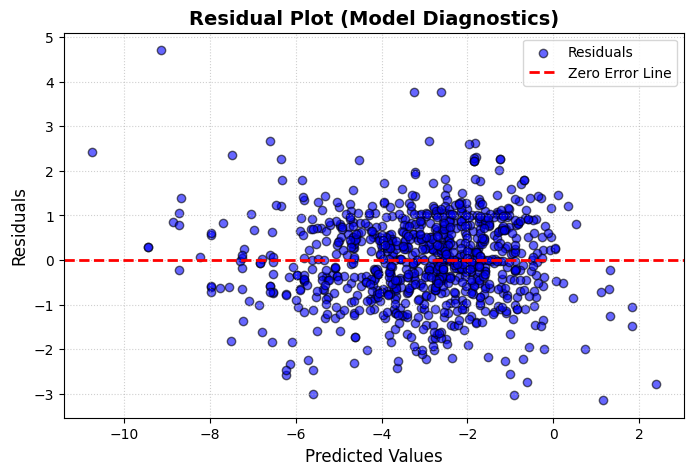

In [106]:
lr_train_res = Y_train - Y_lr_train_pred
plt.figure(figsize=(8, 5))

# Scatter plot of predicted vs residuals
plt.scatter(Y_lr_train_pred, lr_train_res, color='blue', alpha=0.6, edgecolors='k', label='Residuals')

# Add a horizontal line at y=0
plt.axhline(y=0, color='red', linestyle='--', linewidth=2, label='Zero Error Line')

# Labels and Styling
plt.title('Residual Plot (Model Diagnostics)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Values', fontsize=12)
plt.ylabel('Residuals', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

# Display the plot
plt.show()

##Random Forrests

Text(0.5, 0, 'Experimental LogS')

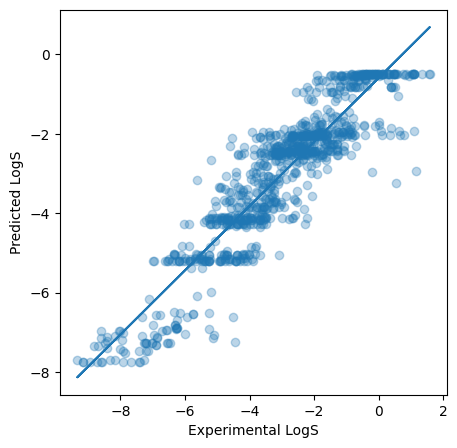

In [107]:
import matplotlib.pyplot as plt
import numpy as np
plt.figure(figsize=(5,5))
plt.scatter (x=Y_train, y = Y_rf_train_pred, alpha=0.3)

z = np.polyfit(Y_train, Y_rf_train_pred,1)
p = np.poly1d(z)

plt.plot(Y_train, p(Y_train))
plt.ylabel('Predicted LogS')
plt.xlabel('Experimental LogS')

###Residuals plot

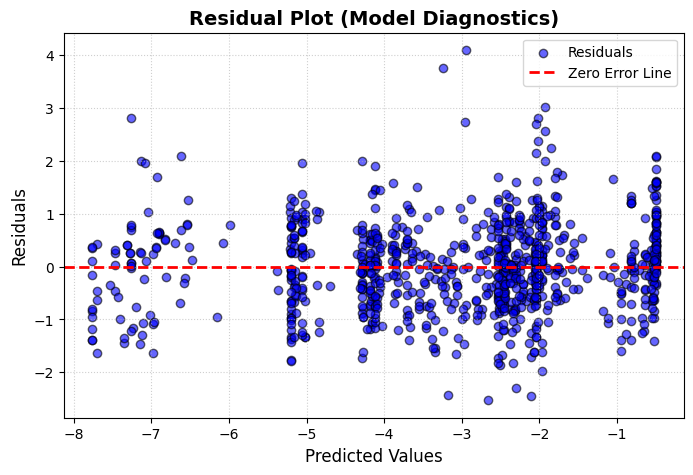

In [108]:
Y_train_rf = Y_train - Y_rf_train_pred
plt.figure(figsize=(8, 5))

# Scatter plot of predicted vs residuals
plt.scatter(Y_rf_train_pred, Y_train_rf, color='blue', alpha=0.6, edgecolors='k', label='Residuals')

# Add a horizontal line at y=0
plt.axhline(y=0, color='red', linestyle='--', linewidth=2, label='Zero Error Line')

# Labels and Styling
plt.title('Residual Plot (Model Diagnostics)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Values', fontsize=12)
plt.ylabel('Residuals', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

# Display the plot
plt.show()

##Stoichastic Gradient Descent




Text(0.5, 0, 'Experimental LogS')

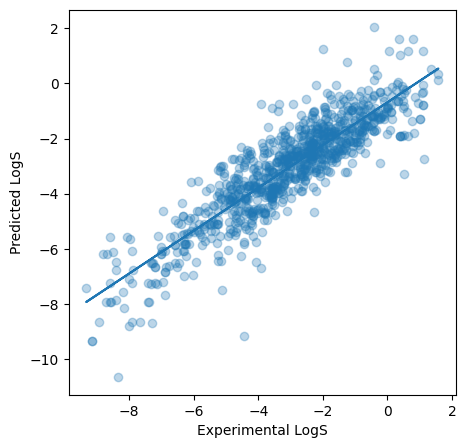

In [109]:
import matplotlib.pyplot as plt
import numpy as np
plt.figure(figsize=(5,5))
plt.scatter (x=Y_train, y = Y_clf_train_pred, alpha=0.3)

z = np.polyfit(Y_train, Y_clf_train_pred,1)
p = np.poly1d(z)

plt.plot(Y_train, p(Y_train))
plt.ylabel('Predicted LogS')
plt.xlabel('Experimental LogS')

###Residuals plot

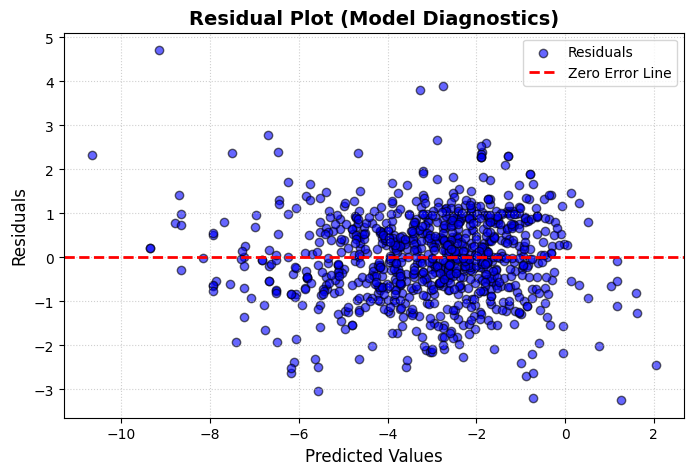

In [110]:
clf_train_res = Y_train - Y_clf_train_pred
plt.figure(figsize=(8, 5))

# Scatter plot of predicted vs residuals
plt.scatter(Y_clf_train_pred, clf_train_res, color='blue', alpha=0.6, edgecolors='k', label='Residuals')

# Add a horizontal line at y=0
plt.axhline(y=0, color='red', linestyle='--', linewidth=2, label='Zero Error Line')

# Labels and Styling
plt.title('Residual Plot (Model Diagnostics)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Values', fontsize=12)
plt.ylabel('Residuals', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

# Display the plot
plt.show()

##Beyesian Ridge Regression


Text(0.5, 0, 'Experimental LogS')

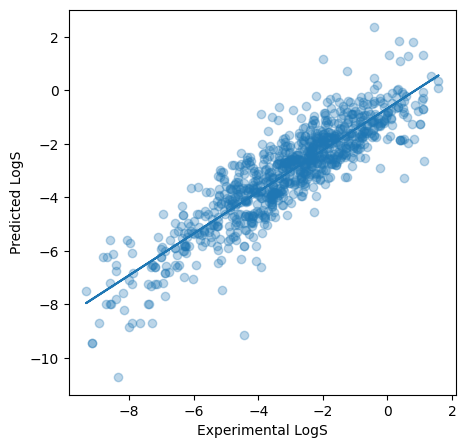

In [111]:
import matplotlib.pyplot as plt
import numpy as np
plt.figure(figsize=(5,5))
plt.scatter (x=Y_train, y = Y_br_train_pred, alpha=0.3)

z = np.polyfit(Y_train, Y_br_train_pred,1)
p = np.poly1d(z)

plt.plot(Y_train, p(Y_train))
plt.ylabel('Predicted LogS')
plt.xlabel('Experimental LogS')

###Residuals plot

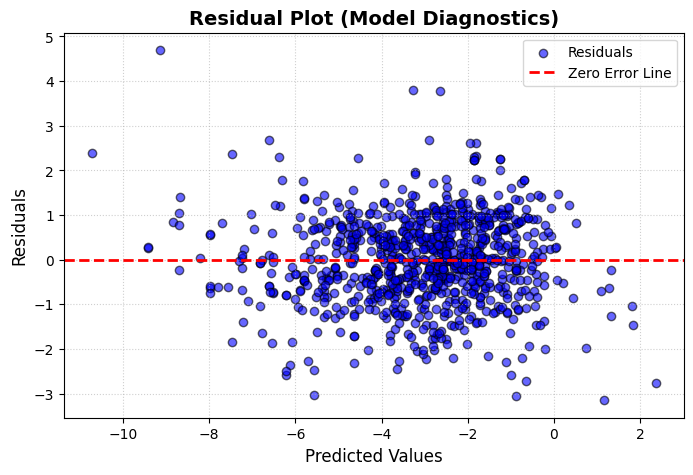

In [112]:
br_train_res = Y_train - Y_br_train_pred
plt.figure(figsize=(8, 5))

# Scatter plot of predicted vs residuals
plt.scatter(Y_br_train_pred, br_train_res, color='blue', alpha=0.6, edgecolors='k', label='Residuals')

# Add a horizontal line at y=0
plt.axhline(y=0, color='red', linestyle='--', linewidth=2, label='Zero Error Line')

# Labels and Styling
plt.title('Residual Plot (Model Diagnostics)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Values', fontsize=12)
plt.ylabel('Residuals', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

# Display the plot
plt.show()

##Baysian Ridge pipeline

Text(0.5, 0, 'Experimental LogS')

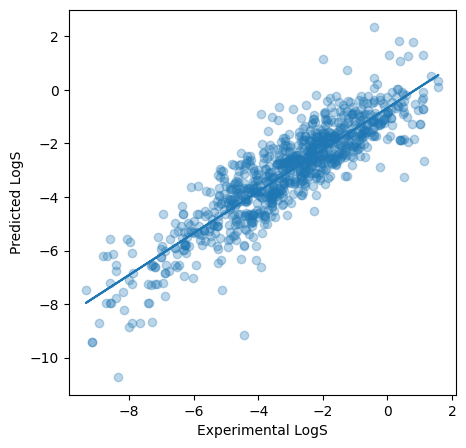

In [113]:
import matplotlib.pyplot as plt
import numpy as np
plt.figure(figsize=(5,5))
plt.scatter (x=Y_train, y = Y_brp_train_pred, alpha=0.3)

z = np.polyfit(Y_train, Y_brp_train_pred,1)
p = np.poly1d(z)

plt.plot(Y_train, p(Y_train))
plt.ylabel('Predicted LogS')
plt.xlabel('Experimental LogS')

###Residuals plot

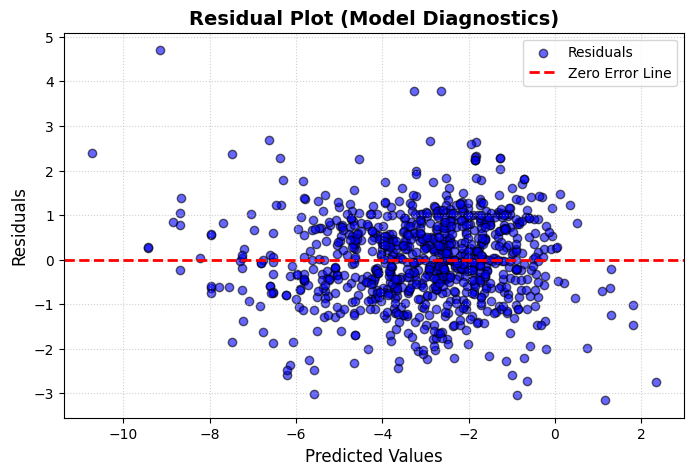

In [114]:
brp_train_res = Y_train - Y_brp_train_pred
plt.figure(figsize=(8, 5))

# Scatter plot of predicted vs residuals
plt.scatter(Y_brp_train_pred, brp_train_res, color='blue', alpha=0.6, edgecolors='k', label='Residuals')

# Add a horizontal line at y=0
plt.axhline(y=0, color='red', linestyle='--', linewidth=2, label='Zero Error Line')

# Labels and Styling
plt.title('Residual Plot (Model Diagnostics)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Values', fontsize=12)
plt.ylabel('Residuals', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

# Display the plot
plt.show()

##K nearest neighbours regression

Text(0.5, 0, 'Experimental LogS')

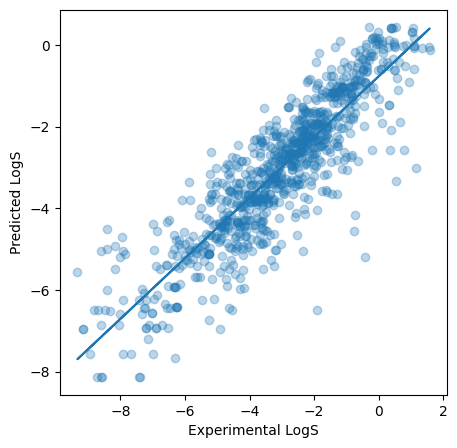

In [115]:
import matplotlib.pyplot as plt
import numpy as np
plt.figure(figsize=(5,5))
plt.scatter (x=Y_train, y = Y_kn_train_pred, alpha=0.3)

z = np.polyfit(Y_train, Y_kn_train_pred,1)
p = np.poly1d(z)

plt.plot(Y_train, p(Y_train))
plt.ylabel('Predicted LogS')
plt.xlabel('Experimental LogS')

###Residuals plot

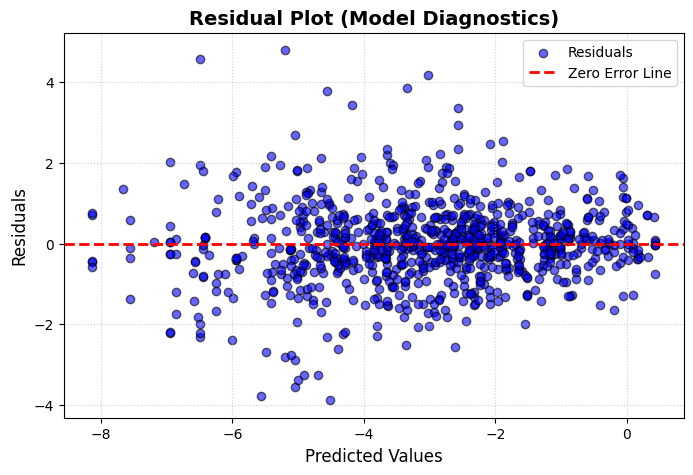

In [116]:
kn_train_res = Y_train - Y_kn_train_pred
plt.figure(figsize=(8, 5))

# Scatter plot of predicted vs residuals
plt.scatter(Y_kn_train_pred, kn_train_res, color='blue', alpha=0.6, edgecolors='k', label='Residuals')

# Add a horizontal line at y=0
plt.axhline(y=0, color='red', linestyle='--', linewidth=2, label='Zero Error Line')

# Labels and Styling
plt.title('Residual Plot (Model Diagnostics)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Values', fontsize=12)
plt.ylabel('Residuals', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

# Display the plot
plt.show()

##BR KNN Ensemble

this model is over fitting consider adgusting params

Text(0.5, 0, 'Experimental LogS')

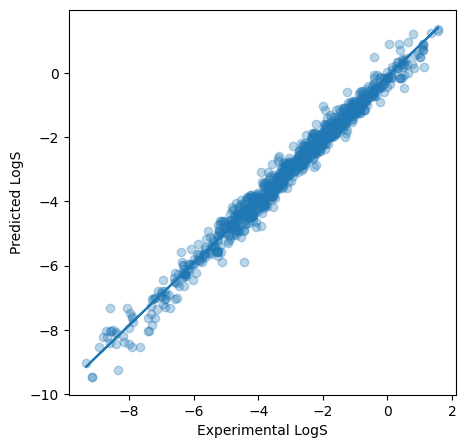

In [117]:
import matplotlib.pyplot as plt
import numpy as np
plt.figure(figsize=(5,5))
plt.scatter (x=Y_train, y = Y_bk_train_pred, alpha=0.3)

z = np.polyfit(Y_train, Y_bk_train_pred,1)
p = np.poly1d(z)

plt.plot(Y_train, p(Y_train))
plt.ylabel('Predicted LogS')
plt.xlabel('Experimental LogS')

###Residuals plot

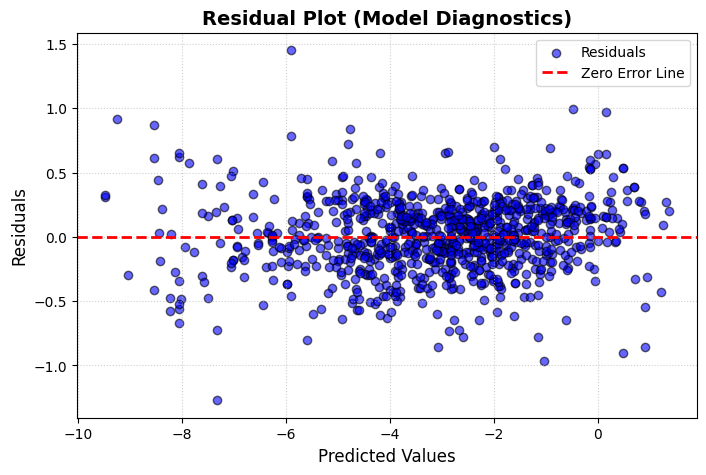

In [118]:
bk_train_res = Y_train - Y_bk_train_pred
plt.figure(figsize=(8, 5))

# Scatter plot of predicted vs residuals
plt.scatter(Y_bk_train_pred, bk_train_res, color='blue', alpha=0.6, edgecolors='k', label='Residuals')

# Add a horizontal line at y=0
plt.axhline(y=0, color='red', linestyle='--', linewidth=2, label='Zero Error Line')

# Labels and Styling
plt.title('Residual Plot (Model Diagnostics)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Values', fontsize=12)
plt.ylabel('Residuals', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

# Display the plot
plt.show()

##Gaussian Process Regression

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
plt.figure(figsize=(5,5))
plt.scatter (x=Y_train, y = Y_gpr_train_pred, alpha=0.3)

z = np.polyfit(Y_train, Y_gpr_train_pred,1)
p = np.poly1d(z)

plt.plot(Y_train, p(Y_train))
plt.ylabel('Predicted LogS')
plt.xlabel('Experimental LogS')

###Residuals plot

In [ ]:
gpr_train_res = Y_train - Y_gpr_train_pred
plt.figure(figsize=(8, 5))

# Scatter plot of predicted vs residuals
plt.scatter(Y_gpr_train_pred, gpr_train_res, color='blue', alpha=0.6, edgecolors='k', label='Residuals')

# Add a horizontal line at y=0
plt.axhline(y=0, color='red', linestyle='--', linewidth=2, label='Zero Error Line')

# Labels and Styling
plt.title('Residual Plot (Model Diagnostics)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Values', fontsize=12)
plt.ylabel('Residuals', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

# Display the plot
plt.show()